In [13]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PLOT_DIR = Path('muon_tag_collab_madison')
PLOT_DIR.mkdir(exist_ok=True)


In [14]:
H5_FILE = '/data/user/tvaneede/muon_tagging/data_processing/output/h5/merged.h5'

with h5py.File(H5_FILE, 'r') as f:
    reco_etot   = f['RecoETot']['value'][:]   # GeV
    reco_zenith = f['RecoZenith']['value'][:]  # radians

reco_cos_theta = np.cos(reco_zenith)
print(f'Data events: {len(reco_etot)}')


Data events: 30


In [15]:
LIVETIME = 411785301.60  # seconds

V8_PATH = (
    '/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/datasets/flavor_globalfit/hese/combined'
    '/IC86_pass2_SnowStorm_v2_FTP_Baseline_Combined_v8-v2_fluxlessweight_PassingHESE_ExtraMuon'
    '/dataset_IC86_pass2_SnowStorm_v2_FTP_Baseline_Combined_v8-v2_fluxlessweight_PassingHESE_ExtraMuon.parquet'
)

df = pd.read_parquet(V8_PATH)
df_muon = df[~np.isnan(df['MuonWeight'])].copy()

sim_energy         = df_muon['reco_energy'].values
sim_cos_theta      = np.cos(df_muon['reco_dir'].values)
sim_weights_conv   = df_muon['MuonWeightCombinedConv'].values   * LIVETIME
sim_weights_prompt = df_muon['MuonWeightCombinedPrompt'].values * LIVETIME
sim_weights_comb   = sim_weights_conv + sim_weights_prompt

print(f'Simulation events: {len(sim_energy)}')
print(f'Conv weighted sum:   {sim_weights_conv.sum():.3f}')
print(f'Prompt weighted sum: {sim_weights_prompt.sum():.3f}')


Simulation events: 191
Conv weighted sum:   6.599
Prompt weighted sum: 26.854


In [16]:
E_THRESHOLD = 60e3   # GeV (60 TeV)
GEO_FACTOR  = 2.1    # geometric acceptance correction

n_total = len(reco_etot)
n_above  = np.sum(reco_etot > E_THRESHOLD)
above_s  = sim_energy > E_THRESHOLD

bins_e      = np.logspace(np.log10(10e3), np.log10(300e3), 30)
bin_cents_e = 0.5 * (bins_e[:-1] + bins_e[1:])

bins_z_full  = np.linspace(-1, 1, 21)
bins_z_half  = np.linspace( 0, 1, 11)
bin_cents_zf = 0.5 * (bins_z_full[:-1] + bins_z_full[1:])
bin_cents_zh = 0.5 * (bins_z_half[:-1] + bins_z_half[1:])

def data_over_sim(n_data, w):
    W    = w.sum()
    frac = n_data * GEO_FACTOR / W
    err  = frac * np.sqrt(1.0/n_data + (np.sqrt((w**2).sum())/W)**2)
    return frac, err

frac_conv_all,   err_conv_all   = data_over_sim(n_total, sim_weights_conv)
frac_conv_above, err_conv_above = data_over_sim(n_above, sim_weights_conv[above_s])
frac_comb_all,   err_comb_all   = data_over_sim(n_total, sim_weights_comb)
frac_comb_above, err_comb_above = data_over_sim(n_above, sim_weights_comb[above_s])

print(f"Scaling factors (data×{GEO_FACTOR} / sim):")
print(f"  Conv  — all: {frac_conv_all:.2f} ± {err_conv_all:.2f},   >60 TeV: {frac_conv_above:.2f} ± {err_conv_above:.2f}")
print(f"  Comb  — all: {frac_comb_all:.2f} ± {err_comb_all:.2f},   >60 TeV: {frac_comb_above:.2f} ± {err_comb_above:.2f}")


Scaling factors (data×2.1 / sim):
  Conv  — all: 9.55 ± 2.30,   >60 TeV: 19.31 ± 8.83
  Comb  — all: 1.88 ± 0.39,   >60 TeV: 1.89 ± 0.82


In [17]:
def _hist_step(ax, vals, bins, cents, weights, color, label):
    w_sum = np.histogram(vals, bins=bins, weights=weights)[0]
    err   = np.sqrt(np.histogram(vals, bins=bins, weights=weights**2)[0])
    ax.stairs(w_sum, bins, color=color, linewidth=1.5, label=label)
    mask = w_sum > 0
    ax.errorbar(cents[mask], w_sum[mask], yerr=err[mask],
                fmt='none', color=color, capsize=3)

def _hist_data(ax, vals, bins, cents, scale, color, label):
    n_raw = np.histogram(vals, bins=bins)[0]
    n_sc  = n_raw * scale
    err   = np.sqrt(n_raw) * scale
    ax.stairs(n_sc, bins, color=color, linewidth=1.5, label=label)
    mask = n_sc > 0
    ax.errorbar(cents[mask], n_sc[mask], yerr=err[mask],
                fmt='none', color=color, capsize=3)

def _finish(ax, bins, xlabel, title, fname, vline=True, logx=True):
    if logx:
        ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_ylim(1e-5, 1e2)
    if vline:
        ax.axvline(E_THRESHOLD if logx else None, color='black',
                   linestyle='--', linewidth=1.5, label='60 TeV threshold')
    ax.set_xlabel(xlabel, fontsize=14)
    ax.set_ylabel('Events', fontsize=14)
    ax.set_title(title, fontsize=13)
    ax.legend(fontsize=12)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / fname, bbox_inches='tight')
    plt.show()


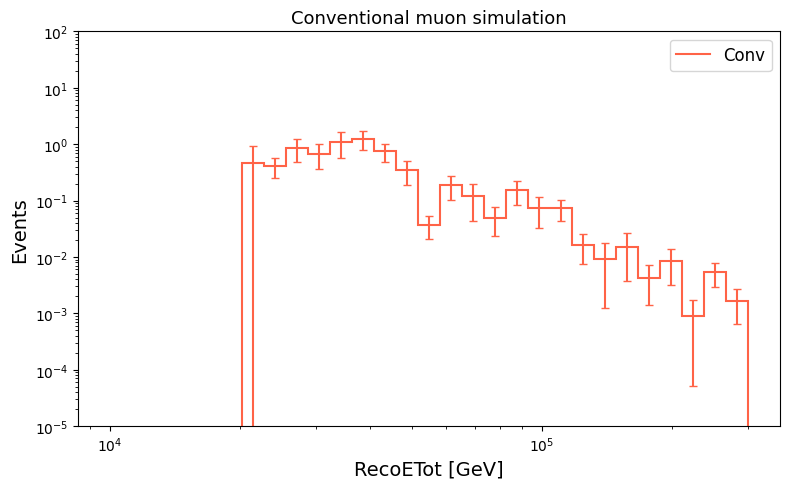

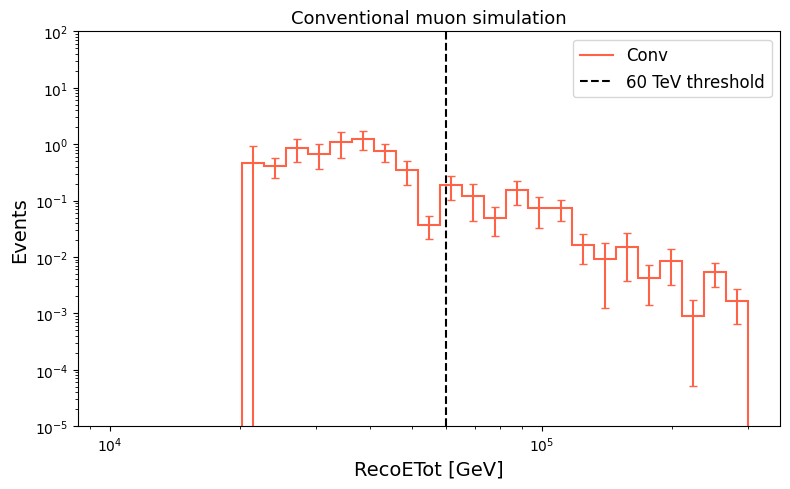

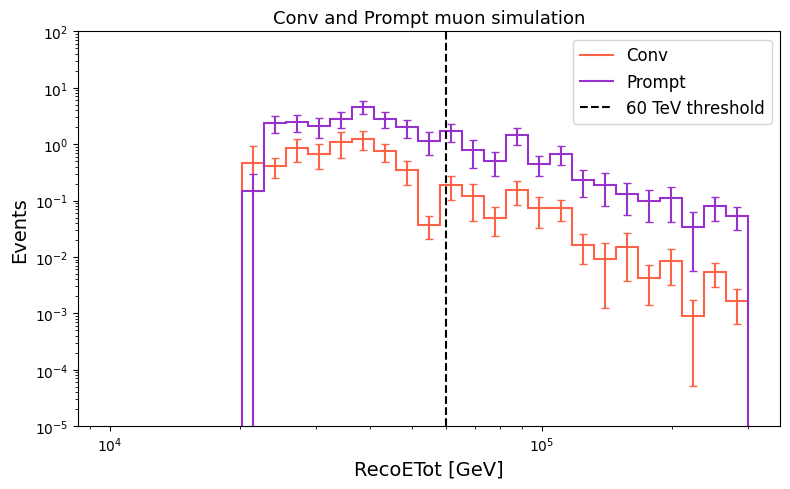

In [18]:
# 1. Conv only, no threshold line
fig, ax = plt.subplots(figsize=(8, 5))
_hist_step(ax, sim_energy, bins_e, bin_cents_e, sim_weights_conv, 'tomato', 'Conv')
_finish(ax, bins_e, 'RecoETot [GeV]', 'Conventional muon simulation', 'e_sim_conv.pdf', vline=False)

# 2. Conv only, with threshold line
fig, ax = plt.subplots(figsize=(8, 5))
_hist_step(ax, sim_energy, bins_e, bin_cents_e, sim_weights_conv, 'tomato', 'Conv')
_finish(ax, bins_e, 'RecoETot [GeV]', 'Conventional muon simulation', 'e_sim_conv_line.pdf', vline=True)

# 3. Conv + Prompt, with threshold line
fig, ax = plt.subplots(figsize=(8, 5))
_hist_step(ax, sim_energy, bins_e, bin_cents_e, sim_weights_conv,   'tomato',     'Conv')
_hist_step(ax, sim_energy, bins_e, bin_cents_e, sim_weights_prompt, 'darkorchid', 'Prompt')
_finish(ax, bins_e, 'RecoETot [GeV]', 'Conv and Prompt muon simulation', 'e_sim_conv_prompt_line.pdf', vline=True)


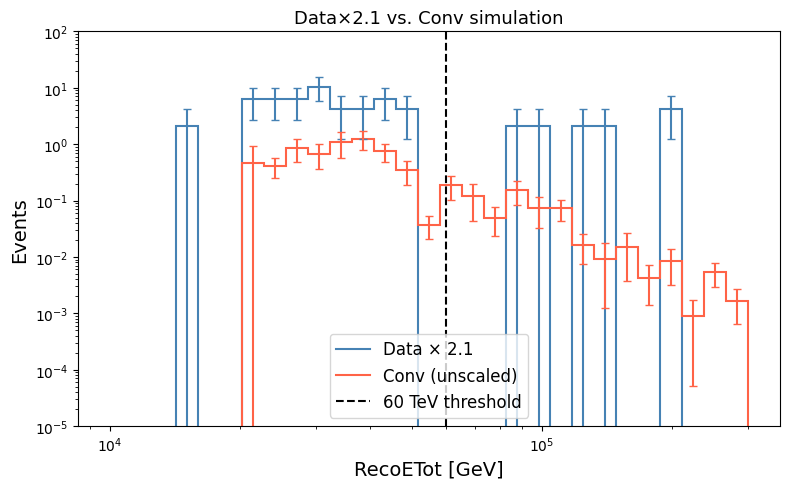

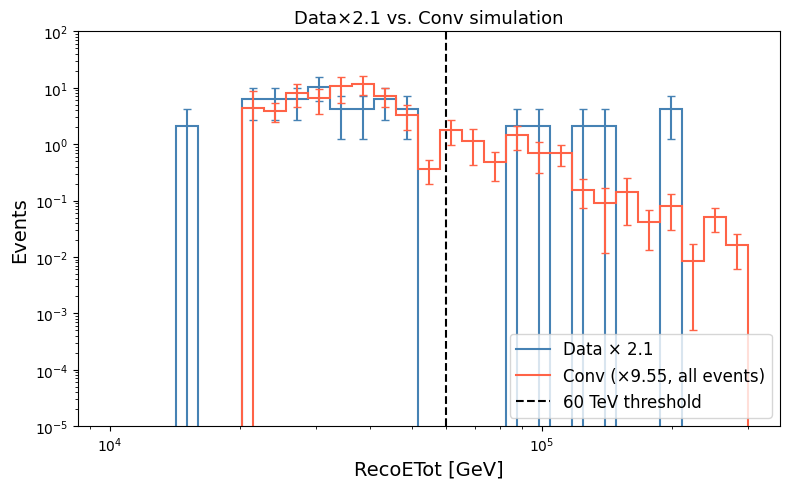

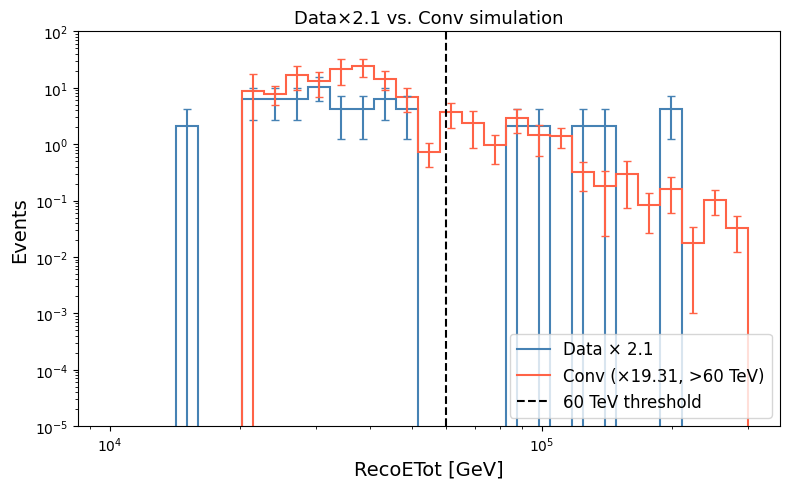

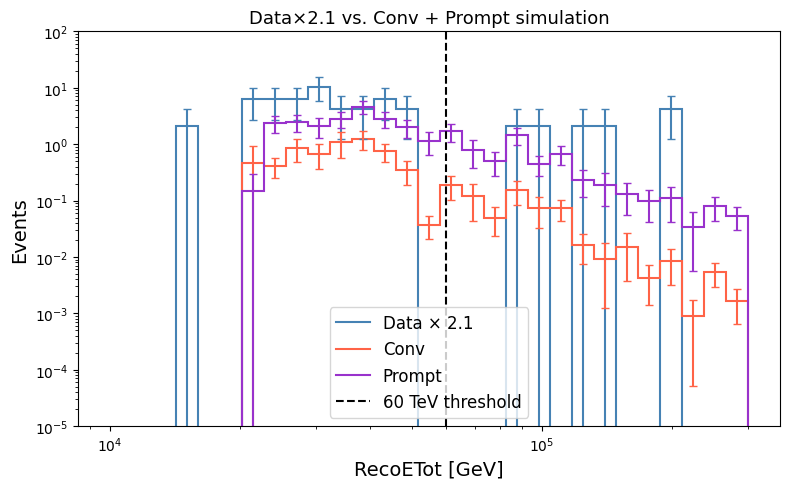

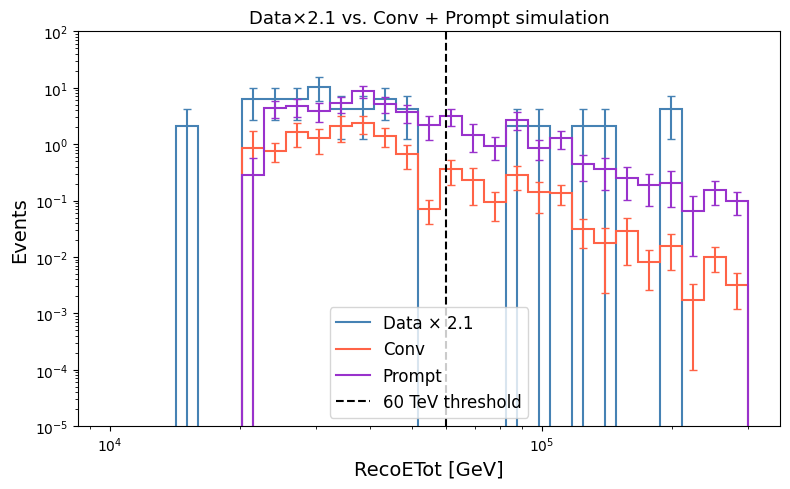

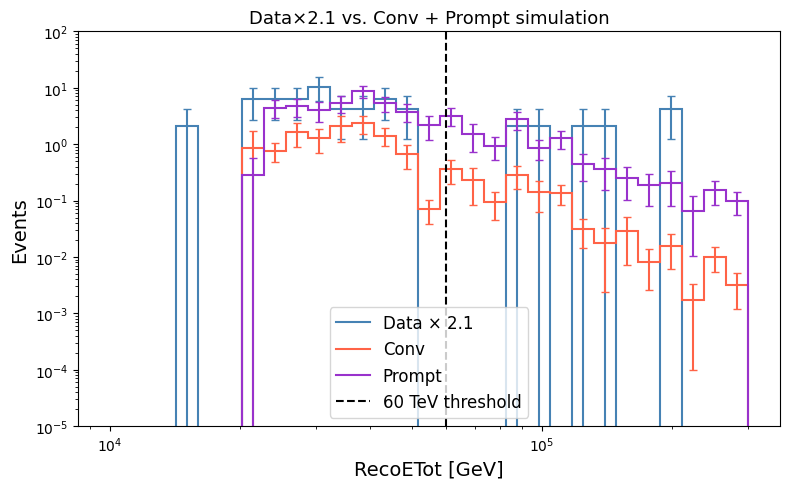

In [19]:
dw = GEO_FACTOR  # scalar scale for data

# Conv simulation
for scale, label_s, fname_s in [
    (1,               'Conv (unscaled)',                               'e_data_conv_unscaled.pdf'),
    (frac_conv_all,   f'Conv (×{frac_conv_all:.2f}, all events)',      'e_data_conv_scaled_all.pdf'),
    (frac_conv_above, f'Conv (×{frac_conv_above:.2f}, >60 TeV)',       'e_data_conv_scaled_above.pdf'),
]:
    fig, ax = plt.subplots(figsize=(8, 5))
    _hist_data(ax, reco_etot, bins_e, bin_cents_e, dw, 'steelblue', f'Data × {GEO_FACTOR}')
    _hist_step(ax, sim_energy, bins_e, bin_cents_e, sim_weights_conv * scale, 'tomato', label_s)
    _finish(ax, bins_e, 'RecoETot [GeV]',
            f'Data×{GEO_FACTOR} vs. Conv simulation', fname_s, vline=True)

# Conv + Prompt simulation
for scale, label_s, fname_s in [
    (1,               'Conv + Prompt (unscaled)',                          'e_data_conv_prompt_unscaled.pdf'),
    (frac_comb_all,   f'Conv + Prompt (×{frac_comb_all:.2f}, all events)', 'e_data_conv_prompt_scaled_all.pdf'),
    (frac_comb_above, f'Conv + Prompt (×{frac_comb_above:.2f}, >60 TeV)',  'e_data_conv_prompt_scaled_above.pdf'),
]:
    fig, ax = plt.subplots(figsize=(8, 5))
    _hist_data(ax, reco_etot, bins_e, bin_cents_e, dw, 'steelblue', f'Data × {GEO_FACTOR}')
    _hist_step(ax, sim_energy, bins_e, bin_cents_e, sim_weights_conv   * scale, 'tomato',     'Conv')
    _hist_step(ax, sim_energy, bins_e, bin_cents_e, sim_weights_prompt * scale, 'darkorchid', 'Prompt')
    _finish(ax, bins_e, 'RecoETot [GeV]',
            f'Data×{GEO_FACTOR} vs. Conv + Prompt simulation', fname_s, vline=True)


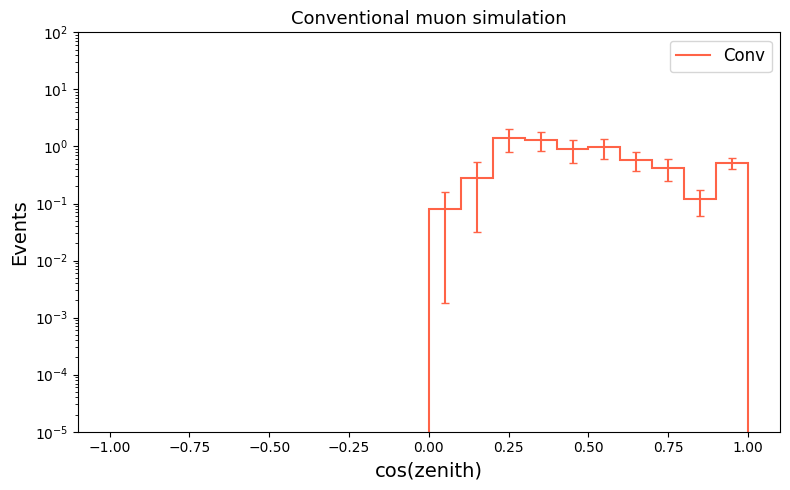

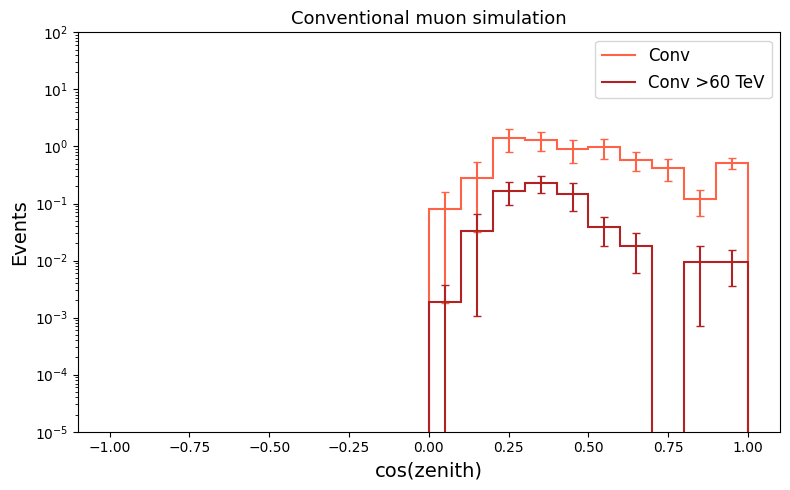

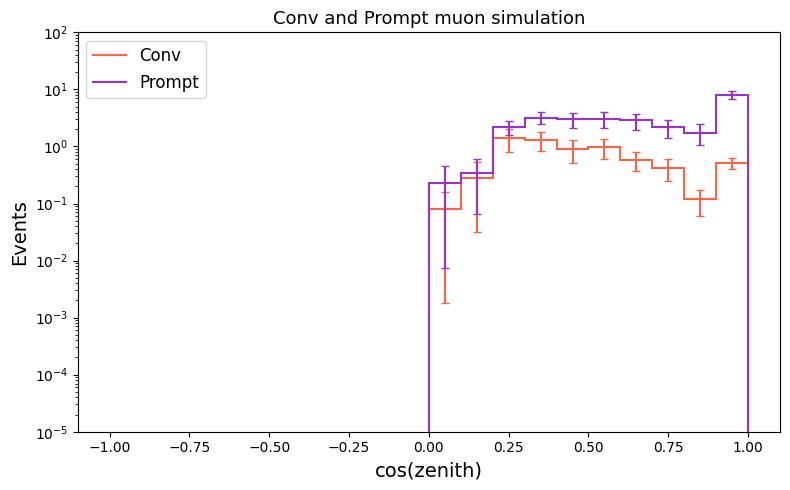

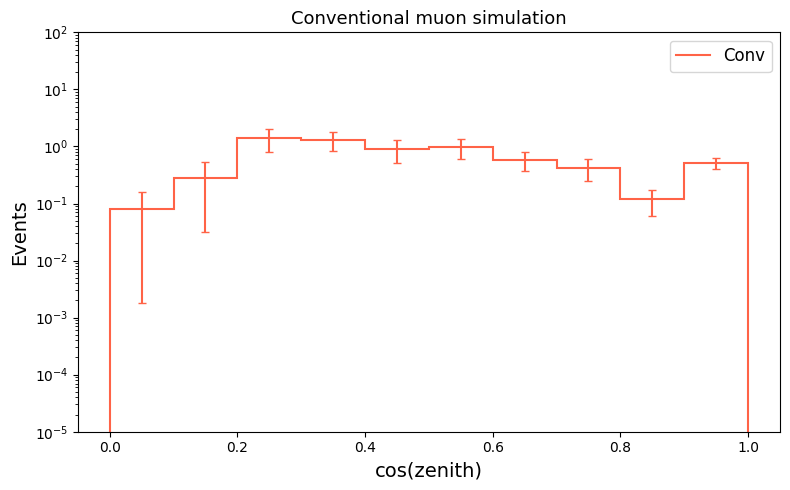

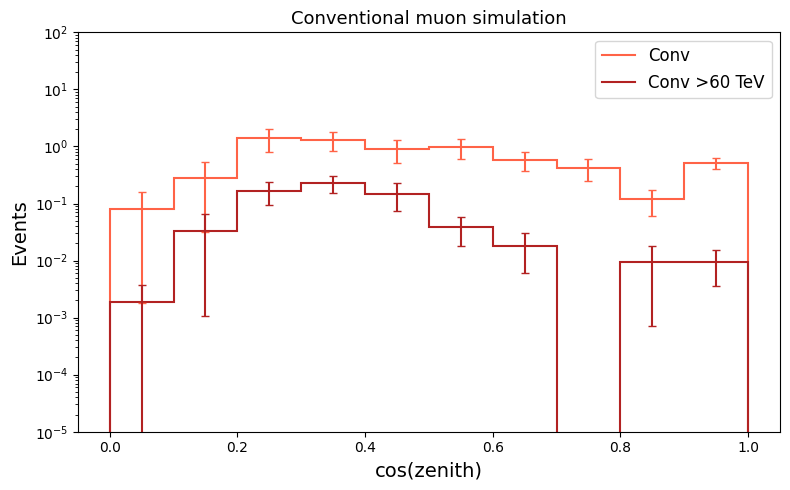

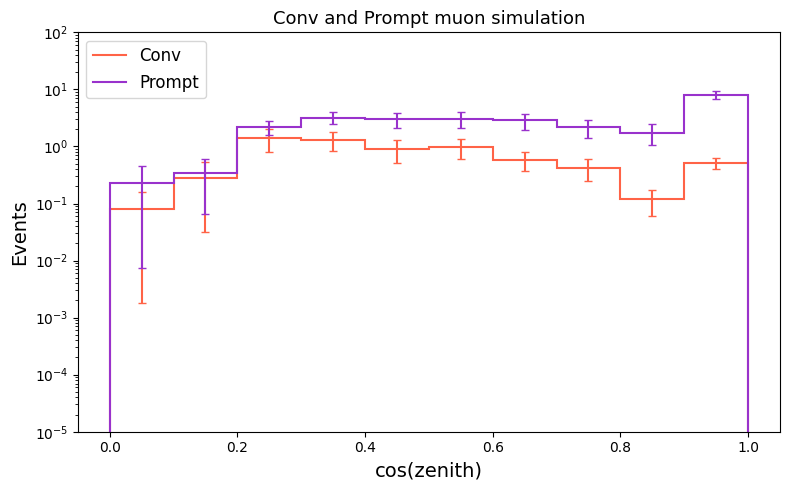

In [20]:
def zen_plots_sim(bins_z, cents_z, tag):
    # 1. Conv only, no >60 TeV overlay
    fig, ax = plt.subplots(figsize=(8, 5))
    _hist_step(ax, sim_cos_theta, bins_z, cents_z, sim_weights_conv, 'tomato', 'Conv')
    ax.set_yscale('log'); ax.set_ylim(1e-5, 1e2)
    ax.set_xlabel('cos(zenith)', fontsize=14); ax.set_ylabel('Events', fontsize=14)
    ax.set_title('Conventional muon simulation', fontsize=13); ax.legend(fontsize=12)
    plt.tight_layout(); plt.savefig(PLOT_DIR / f'zen_{tag}_sim_conv.pdf', bbox_inches='tight'); plt.show()

    # 2. Conv with >60 TeV overlay in distinct colour
    fig, ax = plt.subplots(figsize=(8, 5))
    _hist_step(ax, sim_cos_theta,          bins_z, cents_z, sim_weights_conv,          'tomato',    'Conv')
    _hist_step(ax, sim_cos_theta[above_s], bins_z, cents_z, sim_weights_conv[above_s], 'firebrick', 'Conv >60 TeV')
    ax.set_yscale('log'); ax.set_ylim(1e-5, 1e2)
    ax.set_xlabel('cos(zenith)', fontsize=14); ax.set_ylabel('Events', fontsize=14)
    ax.set_title('Conventional muon simulation', fontsize=13)
    ax.legend(fontsize=12); plt.tight_layout()
    plt.savefig(PLOT_DIR / f'zen_{tag}_sim_conv_line.pdf', bbox_inches='tight'); plt.show()

    # 3. Conv + Prompt
    fig, ax = plt.subplots(figsize=(8, 5))
    _hist_step(ax, sim_cos_theta, bins_z, cents_z, sim_weights_conv,   'tomato',     'Conv')
    _hist_step(ax, sim_cos_theta, bins_z, cents_z, sim_weights_prompt, 'darkorchid', 'Prompt')
    ax.set_yscale('log'); ax.set_ylim(1e-5, 1e2)
    ax.set_xlabel('cos(zenith)', fontsize=14); ax.set_ylabel('Events', fontsize=14)
    ax.set_title('Conv and Prompt muon simulation', fontsize=13); ax.legend(fontsize=12)
    plt.tight_layout(); plt.savefig(PLOT_DIR / f'zen_{tag}_sim_conv_prompt.pdf', bbox_inches='tight'); plt.show()

zen_plots_sim(bins_z_full, bin_cents_zf, 'full')
zen_plots_sim(bins_z_half, bin_cents_zh, 'half')


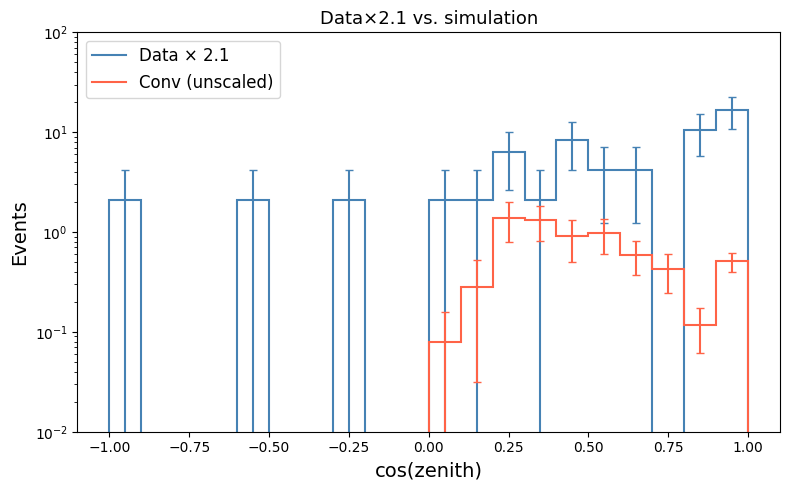

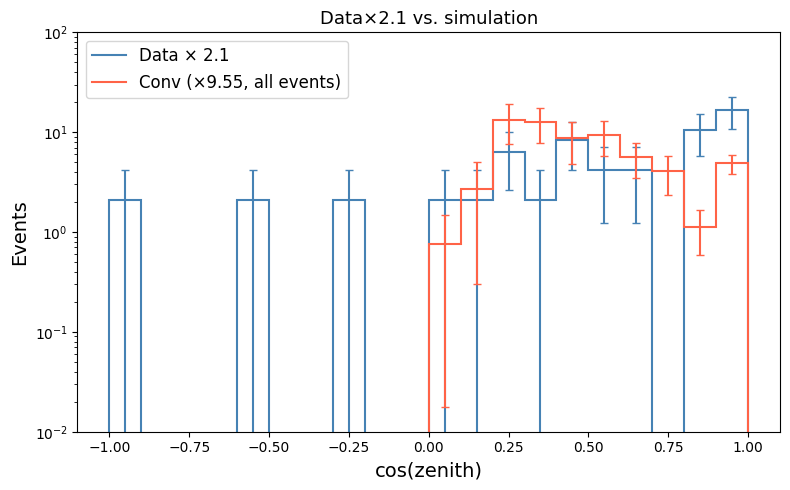

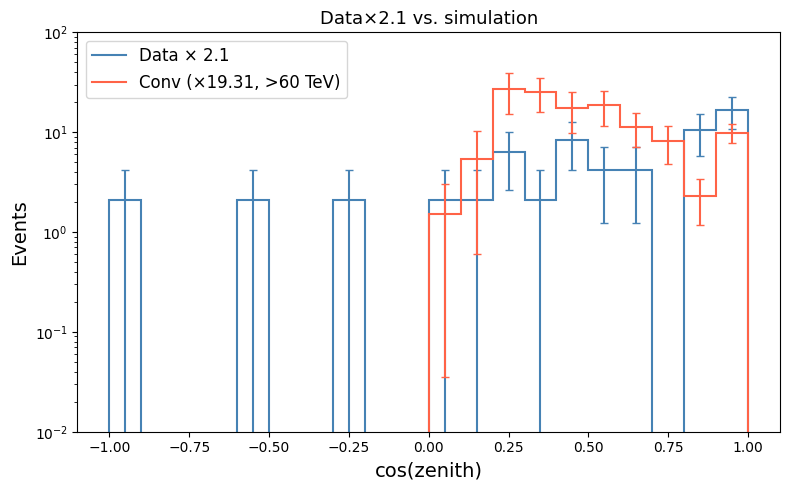

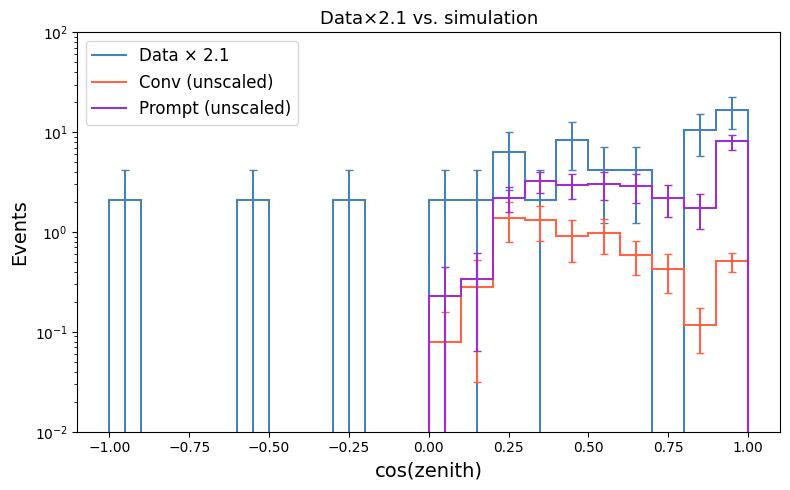

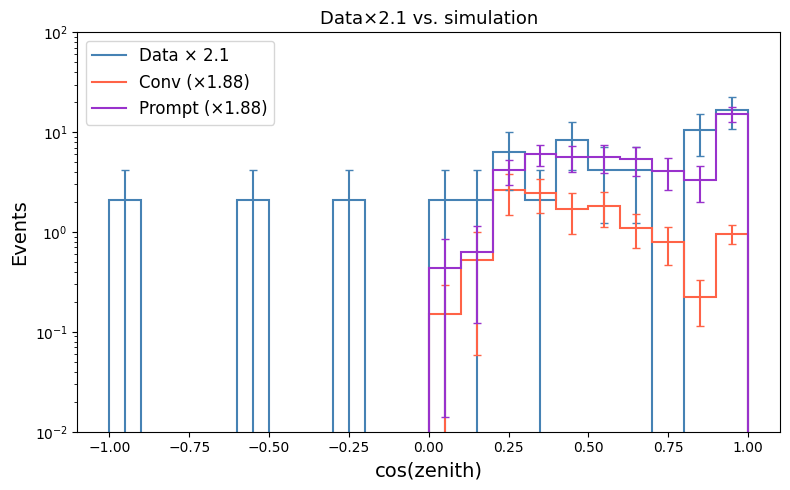

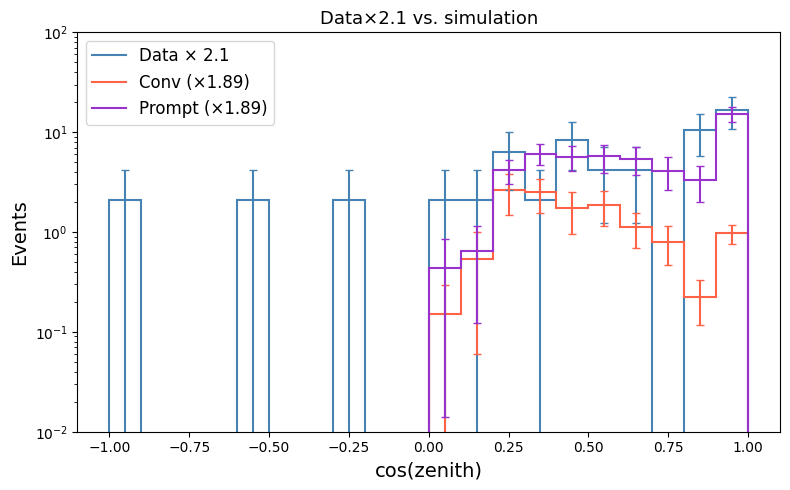

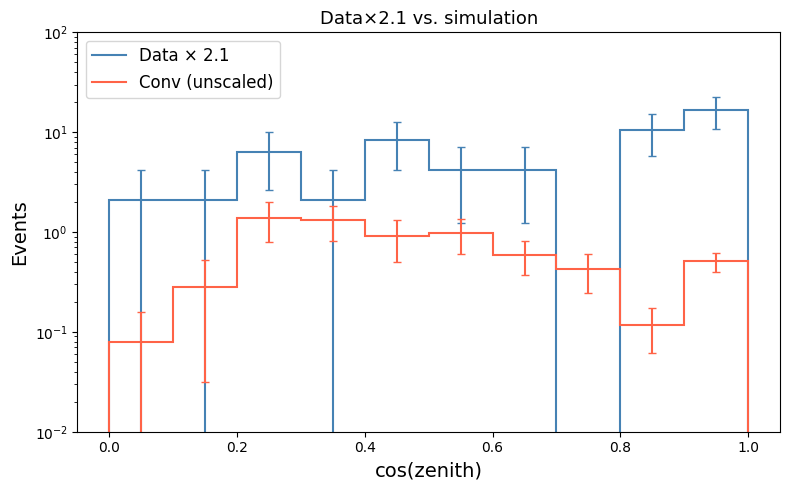

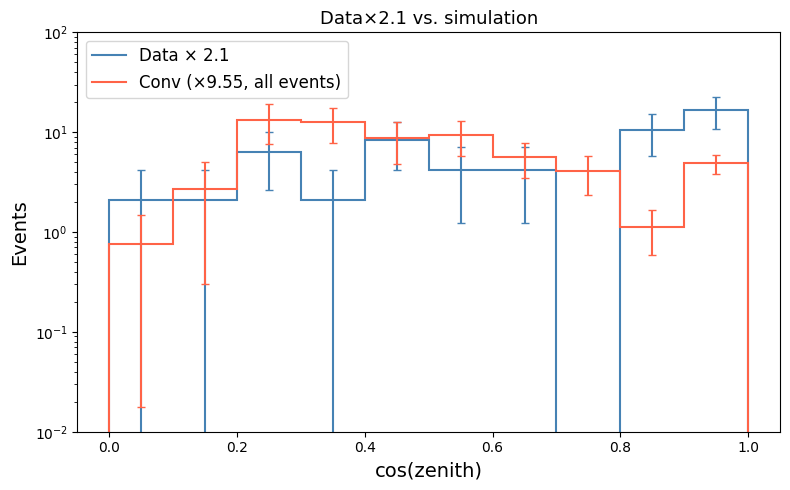

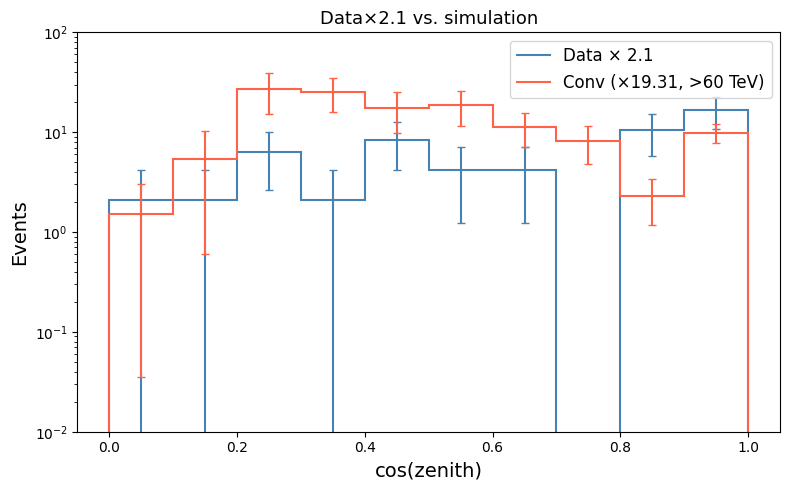

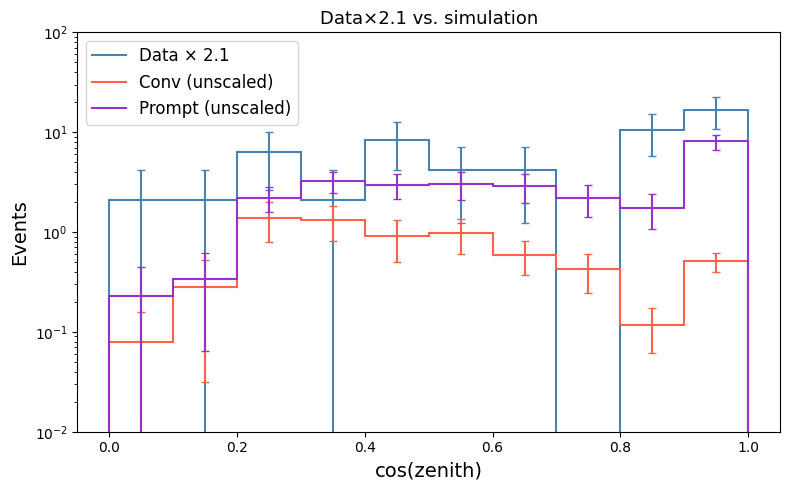

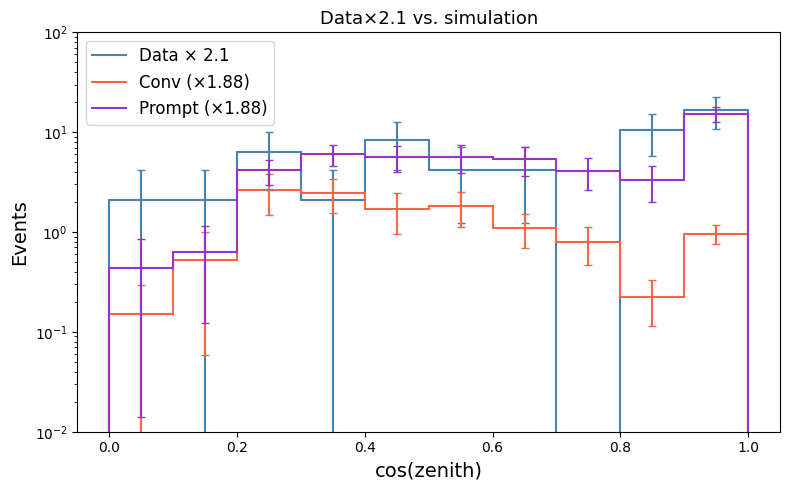

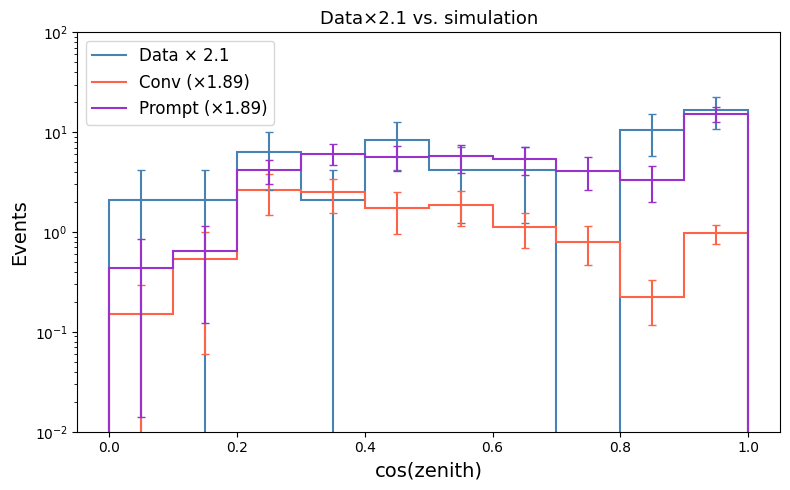

In [21]:
def zen_plots_data(bins_z, cents_z, tag):
    mask_d = reco_cos_theta >= bins_z[0]

    def _plot(w_conv_s, w_prompt_s, label_conv, label_prompt, fname, with_prompt):
        fig, ax = plt.subplots(figsize=(8, 5))
        _hist_data(ax, reco_cos_theta[mask_d], bins_z, cents_z, GEO_FACTOR,
                   'steelblue', f'Data × {GEO_FACTOR}')
        _hist_step(ax, sim_cos_theta, bins_z, cents_z, w_conv_s, 'tomato', label_conv)
        if with_prompt:
            _hist_step(ax, sim_cos_theta, bins_z, cents_z, w_prompt_s, 'darkorchid', label_prompt)
        ax.set_yscale('log'); ax.set_ylim(1e-2, 1e2)
        ax.set_xlabel('cos(zenith)', fontsize=14); ax.set_ylabel('Events', fontsize=14)
        ax.set_title(f'Data×{GEO_FACTOR} vs. simulation', fontsize=13); ax.legend(fontsize=12)
        plt.tight_layout(); plt.savefig(PLOT_DIR / fname, bbox_inches='tight'); plt.show()

    # Conv only
    for scale, lbl, fname in [
        (1,               'Conv (unscaled)',                           f'zen_{tag}_data_conv_unscaled.pdf'),
        (frac_conv_all,   f'Conv (×{frac_conv_all:.2f}, all events)',  f'zen_{tag}_data_conv_scaled_all.pdf'),
        (frac_conv_above, f'Conv (×{frac_conv_above:.2f}, >60 TeV)',   f'zen_{tag}_data_conv_scaled_above.pdf'),
    ]:
        _plot(sim_weights_conv * scale, None, lbl, None, fname, with_prompt=False)

    # Conv + Prompt
    for scale, lbl_c, lbl_p, fname in [
        (1,               'Conv (unscaled)',              'Prompt (unscaled)',              f'zen_{tag}_data_conv_prompt_unscaled.pdf'),
        (frac_comb_all,   f'Conv (×{frac_comb_all:.2f})',   f'Prompt (×{frac_comb_all:.2f})',   f'zen_{tag}_data_conv_prompt_scaled_all.pdf'),
        (frac_comb_above, f'Conv (×{frac_comb_above:.2f})', f'Prompt (×{frac_comb_above:.2f})', f'zen_{tag}_data_conv_prompt_scaled_above.pdf'),
    ]:
        _plot(sim_weights_conv * scale, sim_weights_prompt * scale, lbl_c, lbl_p, fname, with_prompt=True)

zen_plots_data(bins_z_full, bin_cents_zf, 'full')
zen_plots_data(bins_z_half, bin_cents_zh, 'half')
